# Titulo

In [32]:
import sys
!{sys.executable} -m pip install GPy

You should consider upgrading via the 'c:\Users\aeagu\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip' command.


In [1]:
import pandas as pd
import numpy as np
import GPy

In [2]:
epm = pd.read_csv("data/EPMDATA_INTERPOLATED_v2.csv", parse_dates=['date'])
tpm = pd.read_csv("data/TPMDATA_CLEANED.csv", parse_dates=['date'])
epm.columns

Index(['date', 'Sensor 1 (5m)', 'Sensor 2 (10m)', 'Sensor 3 (5m)',
       'Sensor 4 (10m)'],
      dtype='object')

In [3]:
print("Valores unicos del Sensor 1 (5m)", len(epm['Sensor 1 (5m)'].unique()), f"de {len(epm['Sensor 1 (5m)'])}")
print("Valores unicos del Sensor 2 (10m)", len(epm['Sensor 2 (10m)'].unique()), f"de {len(epm['Sensor 2 (10m)'])}")
print("Valores unicos del Sensor 3 (5m)", len(epm['Sensor 3 (5m)'].unique()), f"de {len(epm['Sensor 3 (5m)'])}")
print("Valores unicos del Sensor 4 (10m)", len(epm['Sensor 4 (10m)'].unique()), f"de {len(epm['Sensor 4 (10m)'])}")

Valores unicos del Sensor 1 (5m) 19 de 885
Valores unicos del Sensor 2 (10m) 45 de 885
Valores unicos del Sensor 3 (5m) 25 de 885
Valores unicos del Sensor 4 (10m) 10 de 885


# Generación de GP lineal

In [7]:
def evaluar_kernel(kernel, nombre_kernel, t_train, y_train, t_hidden, y_hidden_true,
                    y_mean, y_std, t, mask_hidden, serie):
    """
    Entrena un GP univariado con el kernel dado sobre el hueco sintético ya definido
    (t_train/y_train excluyen el hueco; t_hidden/y_hidden_true son los puntos ocultos),
    calcula RMSE/MAE/cobertura al 95%, grafica, y devuelve las métricas para comparar
    entre kernels.
    """
    modelo = GPy.models.GPRegression(t_train, y_train, kernel)
    modelo.optimize(messages=False)
    print(modelo.kern)

    y_pred_norm, y_var_norm = modelo.predict(t_hidden)
    y_pred_norm = y_pred_norm.flatten()
    y_std_pred_norm = np.sqrt(y_var_norm.flatten())

    y_pred_mm = y_pred_norm * y_std + y_mean
    y_hidden_true_mm = y_hidden_true * y_std + y_mean
    y_std_pred_mm = y_std_pred_norm * y_std

    rmse = np.sqrt(np.mean((y_pred_mm - y_hidden_true_mm) ** 2))
    mae = np.mean(np.abs(y_pred_mm - y_hidden_true_mm))
    z95_lo = y_pred_mm - 1.96 * y_std_pred_mm
    z95_hi = y_pred_mm + 1.96 * y_std_pred_mm
    cobertura = np.mean((y_hidden_true_mm >= z95_lo) & (y_hidden_true_mm <= z95_hi))

    print(f"[{nombre_kernel}] RMSE: {rmse:.4f} mm | MAE: {mae:.4f} mm | Cobertura 95%: {cobertura*100:.1f}%")

    t_dias = t / 24
    fig, ax = plt.subplots(figsize=(11, 5))
    ax.plot(t_dias[~mask_hidden], y_norm[~mask_hidden] * y_std + y_mean, '-', color='steelblue', linewidth=1, label='Datos de entrenamiento')
    ax.plot(t_dias[mask_hidden], y_hidden_true_mm, '-o', color='black', linewidth=1.5, markersize=4, label='Valor real (oculto)')
    ax.plot(t_dias[mask_hidden], y_pred_mm, '-', color='crimson', linewidth=2, label=f'Predicción GP ({nombre_kernel})')
    ax.fill_between(t_dias[mask_hidden], z95_lo, z95_hi, color='crimson', alpha=0.2, label='Intervalo 95%')
    ax.set_xlabel('Tiempo (días desde el inicio)')
    ax.set_ylabel(f'{serie} [mm]')
    ax.set_title(f'GP con kernel {nombre_kernel} - {serie} - RMSE={rmse:.3f} mm')
    ax.legend()
    plt.tight_layout()
    plt.show()

    return {'kernel': nombre_kernel, 'rmse': rmse, 'mae': mae, 'cobertura_95': cobertura}


**Parámetros del hueco sintético (confirmados como definitivos para el Paso 1 del ablation study):**
`gap_start=200`, `gap_len=500` → 500 puntos × 6h = 125 días de hueco simulado sobre
`Sensor 2 (10m)`.

  rbf.         |                value  |  constraints  |  priors
  variance     |  0.36483863844889663  |      +ve      |        
  lengthscale  |   139.19061701842182  |      +ve      |        
RMSE: 2.4185 mm
MAE:  2.1157 mm
Cobertura intervalo 95%: 95.6%


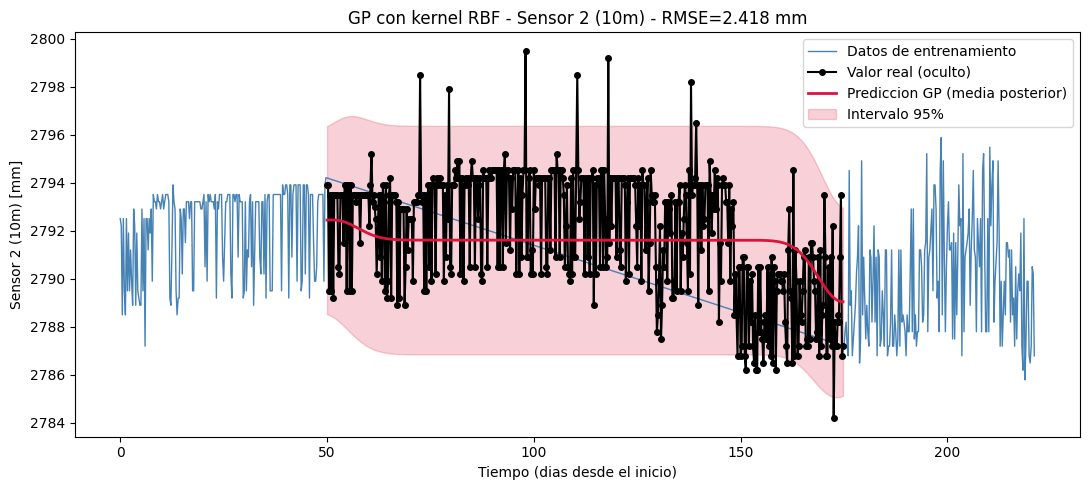

In [8]:
#Seleccion de la serie
serie = 'Sensor 2 (10m)'
y = epm[serie].values
t = (epm["date"]-epm["date"].min()).dt.total_seconds().values / 3600

#Normalizo los datos de la serie de tiempo
y_mean, y_std = y.mean(), y.std()
y_norm = (y - y_mean) / y_std

#<Defino los criterios de la mascara para la venta sin datos
gap_start = 200 
gap_len = 500
mask_hidden = np.zeros(len(y_norm), dtype=bool)
mask_hidden[gap_start:gap_start+gap_len] = True

#Defino el conjunto de entrenamiento
t_train = t[~mask_hidden].reshape(-1,1)
y_train = y_norm[~mask_hidden].reshape(-1,1)

#Corro el GP
kernel = GPy.kern.RBF(input_dim=1, variance=1.0, lengthscale=100.0)
#kernel.lengthscale.fix()
modelo = GPy.models.GPRegression(t_train, y_train, kernel)
modelo.optimize(messages=False)
print(modelo.kern)

#-----------------------------------------------------------------
#Extraigo los puntos de la brecha (los que oculté) para comparar contra la prediccion
t_hidden = t[mask_hidden].reshape(-1,1)
y_hidden_true = y_norm[mask_hidden]   # valor real (normalizado), que el modelo NO vio

#Prediccion del GP sobre la brecha: media posterior y varianza posterior
y_pred_norm, y_var_norm = modelo.predict(t_hidden)
y_pred_norm = y_pred_norm.flatten()
y_std_pred_norm = np.sqrt(y_var_norm.flatten())

#Devuelvo todo a la escala original (mm), usando el mismo y_mean/y_std con que normalice
y_pred_mm = y_pred_norm * y_std + y_mean
y_hidden_true_mm = y_hidden_true * y_std + y_mean
y_std_pred_mm = y_std_pred_norm * y_std   # ojo: la desviacion NO lleva +y_mean, solo se escala

#Metricas de error en mm
rmse = np.sqrt(np.mean((y_pred_mm - y_hidden_true_mm)**2))
mae = np.mean(np.abs(y_pred_mm - y_hidden_true_mm))
print(f"RMSE: {rmse:.4f} mm")
print(f"MAE:  {mae:.4f} mm")

#Cobertura del intervalo de confianza al 95%
z95_lo = y_pred_mm - 1.96*y_std_pred_mm
z95_hi = y_pred_mm + 1.96*y_std_pred_mm
cobertura = np.mean((y_hidden_true_mm >= z95_lo) & (y_hidden_true_mm <= z95_hi))
print(f"Cobertura intervalo 95%: {cobertura*100:.1f}%")

#Grafico
import matplotlib.pyplot as plt

t_dias = t/24  # paso de horas a dias, solo para que el eje x sea mas legible

fig, ax = plt.subplots(figsize=(11,5))
ax.plot(t_dias[~mask_hidden], y[~mask_hidden], '-', color='steelblue', linewidth=1, label='Datos de entrenamiento')
ax.plot(t_dias[mask_hidden], y[mask_hidden], '-o', color='black', linewidth=1.5, markersize=4, label='Valor real (oculto)')
ax.plot(t_dias[mask_hidden], y_pred_mm, '-', color='crimson', linewidth=2, label='Prediccion GP (media posterior)')
ax.fill_between(t_dias[mask_hidden], z95_lo, z95_hi, color='crimson', alpha=0.2, label='Intervalo 95%')
ax.set_xlabel('Tiempo (dias desde el inicio)')
ax.set_ylabel(f'{serie} [mm]')
ax.set_title(f'GP con kernel RBF - {serie} - RMSE={rmse:.3f} mm')
ax.legend()
plt.tight_layout()
plt.show()

In [9]:
# Baseline de interpolación lineal — para poder verificar la afirmación
# "RMSE del GP univariado ≈ RMSE de interpolación lineal" antes de reportarla.
y_norm_series = pd.Series(y_norm)
y_norm_series[mask_hidden] = np.nan
y_interp_norm = y_norm_series.interpolate(method='linear').values
y_interp_mm = y_interp_norm * y_std + y_mean

rmse_interp = np.sqrt(np.mean((y_interp_mm[mask_hidden] - y_hidden_true_mm) ** 2))
mae_interp = np.mean(np.abs(y_interp_mm[mask_hidden] - y_hidden_true_mm))
print(f"RMSE interpolación lineal: {rmse_interp:.4f} mm")
print(f"MAE interpolación lineal:  {mae_interp:.4f} mm")


RMSE interpolación lineal: 2.7233 mm
MAE interpolación lineal:  2.1720 mm


## Con kernel Matérn

  Mat52.       |               value  |  constraints  |  priors
  variance     |  0.3957219300826282  |      +ve      |        
  lengthscale  |  216.71315710684442  |      +ve      |        
RMSE: nan mm
MAE:  nan mm
Cobertura intervalo 95%: 0.0%


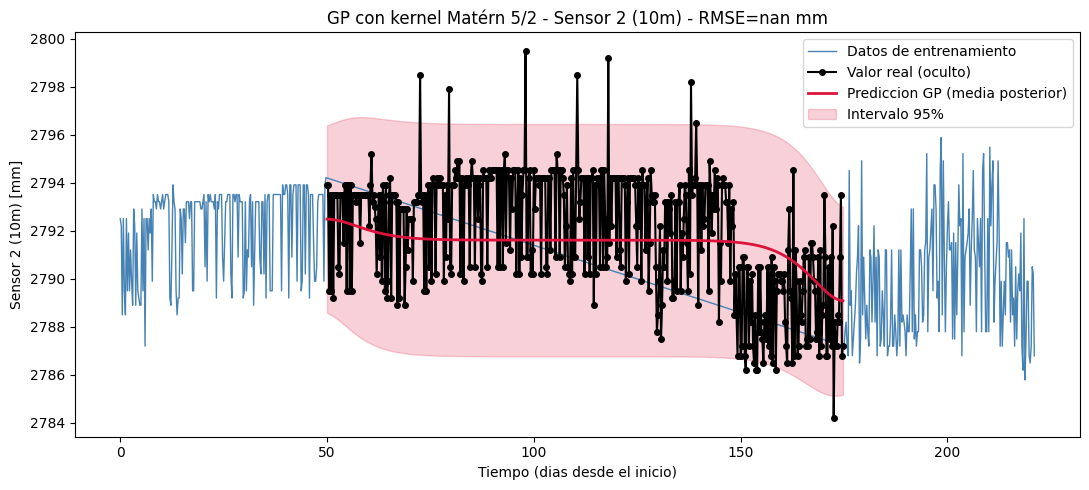

In [10]:
#kernel = GPy.kern.Matern32(input_dim=1, variance=1.0, lengthscale=10.0)
kernel = GPy.kern.Matern52(input_dim=1, variance=1.0, lengthscale=10.0)
#kernel = GPy.kern.OU(input_dim=1, variance=1.0, lengthscale=10.0)   # Matern 1/2

modelo = GPy.models.GPRegression(t_train, y_train, kernel)
modelo.optimize(messages=False)
print(modelo.kern)
#-----------------------------------------------------------------
#Extraigo los puntos de la brecha (los que oculté) para comparar contra la prediccion
t_hidden = t[mask_hidden].reshape(-1,1)
y_hidden_true = y_norm[mask_hidden]   # valor real (normalizado), que el modelo NO vio

#Prediccion del GP sobre la brecha: media posterior y varianza posterior
y_pred_norm, y_var_norm = modelo.predict(t_hidden)
y_pred_norm = y_pred_norm.flatten()
y_std_pred_norm = np.sqrt(y_var_norm.flatten())

#Devuelvo todo a la escala original (mm), usando el mismo y_mean/y_std con que normalice
y_pred_mm = y_pred_norm * y_std + y_mean
y_hidden_true_mm = y_hidden_true * y_std + y_mean
y_std_pred_mm = y_std_pred_norm * y_std   # ojo: la desviacion NO lleva +y_mean, solo se escala

#Metricas de error en mm
rmse = np.sqrt(np.mean((y_pred_mm - y_hidden_true_mm)**2))
mae = np.mean(np.abs(y_pred_mm - y_hidden_true_mm))
print(f"RMSE: {rmse:.4f} mm")
print(f"MAE:  {mae:.4f} mm")

#Cobertura del intervalo de confianza al 95%
z95_lo = y_pred_mm - 1.96*y_std_pred_mm
z95_hi = y_pred_mm + 1.96*y_std_pred_mm
cobertura = np.mean((y_hidden_true_mm >= z95_lo) & (y_hidden_true_mm <= z95_hi))
print(f"Cobertura intervalo 95%: {cobertura*100:.1f}%")

#Grafico
import matplotlib.pyplot as plt

t_dias = t/24  # paso de horas a dias, solo para que el eje x sea mas legible

fig, ax = plt.subplots(figsize=(11,5))
ax.plot(t_dias[~mask_hidden], y[~mask_hidden], '-', color='steelblue', linewidth=1, label='Datos de entrenamiento')
ax.plot(t_dias[mask_hidden], y[mask_hidden], '-o', color='black', linewidth=1.5, markersize=4, label='Valor real (oculto)')
ax.plot(t_dias[mask_hidden], y_pred_mm, '-', color='crimson', linewidth=2, label='Prediccion GP (media posterior)')
ax.fill_between(t_dias[mask_hidden], z95_lo, z95_hi, color='crimson', alpha=0.2, label='Intervalo 95%')
ax.set_xlabel('Tiempo (dias desde el inicio)')
ax.set_ylabel(f'{serie} [mm]')
ax.set_title(f'GP con kernel Matérn 5/2 - {serie} - RMSE={rmse:.3f} mm')
ax.legend()
plt.tight_layout()
plt.show()

  Mat32.       |                value  |  constraints  |  priors
  variance     |  0.43409627225086433  |      +ve      |        
  lengthscale  |    299.7348073774357  |      +ve      |        
[Matérn 3/2] RMSE: nan mm | MAE: nan mm | Cobertura 95%: 0.0%


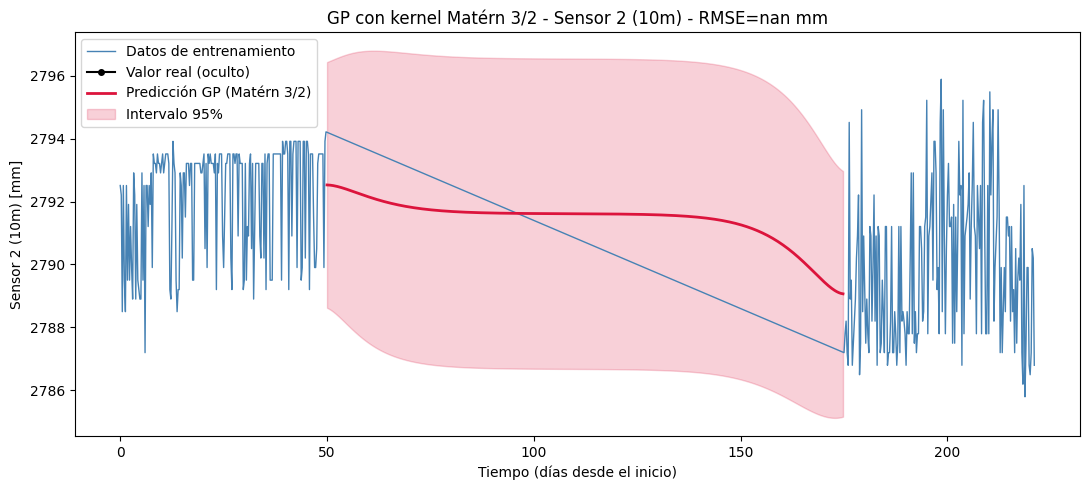

  sum.                      |                  value  |  constraints  |  priors
  Mat32.variance            |     0.4340163553980191  |      +ve      |        
  Mat32.lengthscale         |     299.58352168175446  |      +ve      |        
  std_periodic.variance     |  7.330636191645612e-06  |      +ve      |        
  std_periodic.period       |      62.05135261230908  |      +ve      |        
  std_periodic.lengthscale  |      19.69511389178364  |      +ve      |        
[Matérn 3/2 + Periódico] RMSE: nan mm | MAE: nan mm | Cobertura 95%: 0.0%


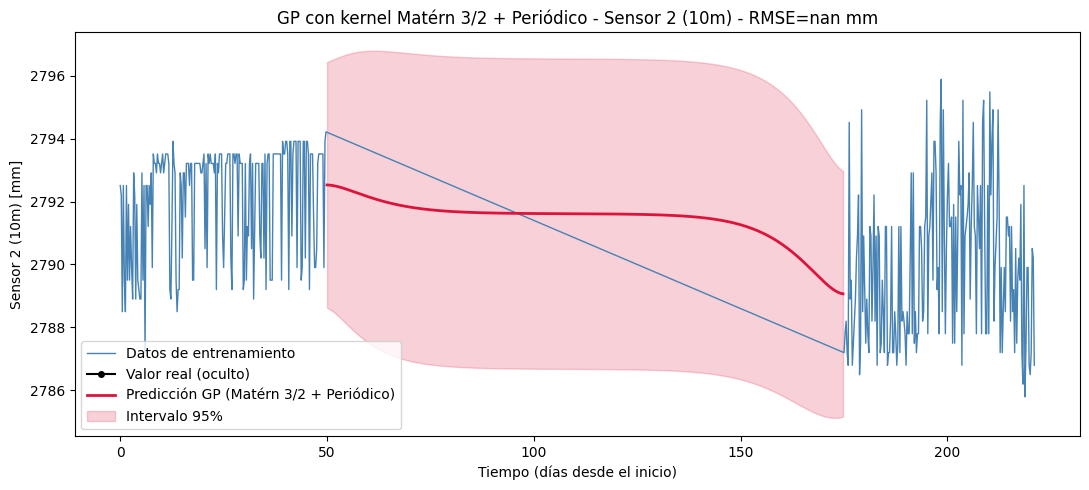

                   kernel  rmse  mae  cobertura_95
0              Matérn 3/2   NaN  NaN           0.0
1  Matérn 3/2 + Periódico   NaN  NaN           0.0


In [11]:
resultados_kernels = []

# Matérn 3/2 solo — misma familia de suavidad que el kernel de Nishihara ya derivado
kernel_m32 = GPy.kern.Matern32(input_dim=1, variance=1.0, lengthscale=100.0)
resultados_kernels.append(
    evaluar_kernel(kernel_m32, "Matérn 3/2", t_train, y_train, t_hidden, y_hidden_true,
                   y_mean, y_std, t, mask_hidden, serie)
)

# Matérn 3/2 + Periódico — separa la tendencia de fluencia del ciclo diario
kernel_compuesto = (
    GPy.kern.Matern32(input_dim=1, variance=1.0, lengthscale=100.0)
    + GPy.kern.StdPeriodic(input_dim=1, variance=0.5, period=24.0, lengthscale=24.0)
)
resultados_kernels.append(
    evaluar_kernel(kernel_compuesto, "Matérn 3/2 + Periódico", t_train, y_train, t_hidden,
                   y_hidden_true, y_mean, y_std, t, mask_hidden, serie)
)

print(pd.DataFrame(resultados_kernels))


# CCM — selección del par TPM-EPM para el Paso 2 del MOGP

Esta sección adapta el análisis de Convergent Cross Mapping (CCM) que ya se había corrido en `tpm y ccm.ipynb` (la sección `#CCM` de ese cuaderno), pero usando los archivos de datos locales de este proyecto (`data/EPMDATA_INTERPOLATED_v2.csv`, `data/TPMDATA_CLEANED.csv`) en vez de las rutas de Google Drive del cuaderno original.

**Objetivo:** identificar, para EPM Sensor 1 (5m), cuál de las 14 series TPM (POT(1..7), Tilt(1..7)) tiene mayor CCM skill hacia él. Ese par es el que `funciones_vector_valuadas.md` (sección 6) pide usar como el caso $D=2$ del Paso 2 del ablation study (MOGP-ICM).

**Nota importante sobre alineación temporal:** a diferencia del MOGP (que maneja datos heterotópicos de forma nativa y por eso NO se sincronizan artificialmente los relojes de EPM y TPM — ver sección 5 del documento), el método CCM sí necesita que ambas series compartan una única rejilla temporal para construir el espacio de estados. Por eso, y solo para este análisis, se alinea TPM sobre la rejilla de EPM (desfase estructural constante de 1h entre ambos). Esta alineación no se usa en el entrenamiento del MOGP.

In [10]:
import sys
!{sys.executable} -m pip install pyEDM

You should consider upgrading via the 'c:\Users\aeagu\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip' command.


In [4]:
import pyEDM
from itertools import product

In [6]:
#Alineo TPM sobre la rejilla de EPM solo para el CCM (ver nota de la celda markdown anterior).
#'freq' no es una serie de deformación/inclinación, se descarta antes de construir el dataframe del CCM.
df_ccm = pd.merge_asof(
    epm.sort_values('date'),
    tpm.drop(columns=['freq']).sort_values('date'),
    on='date',
    direction='nearest',
    tolerance=pd.Timedelta('3h'),
)
df_ccm = df_ccm.dropna().reset_index(drop=True)

#pyEDM (2.5.7) no maneja bien una columna datetime64[ns] como parte del dataFrame
#(revienta con "Cannot convert from specific units to generic units in NumPy
#datetimes or timedeltas"). La descartamos aqui -- igual que hacia tpm y ccm.ipynb
#con epm.drop(columns=["date"]) -- y dejamos que pyEDM use el indice posicional (fila)
#como eje temporal, que es justo lo que esperan los rangos "1 600" de lib/pred.
df_ccm = df_ccm.drop(columns=['date'])

print(f"Filas EPM: {len(epm)}, filas TPM: {len(tpm)}, filas alineadas para CCM: {len(df_ccm)}")

Filas EPM: 885, filas TPM: 884, filas alineadas para CCM: 884


In [9]:
#Optimización de la dimensión de embebido E para cada una de las 18 series (igual que en tpm y ccm.ipynb)
columnas_tpm_epm = ['POT(1)','POT(2)','POT(3)','POT(4)','POT(5)','POT(6)','POT(7)',
                     'Tilt(1)','Tilt(2)','Tilt(3)','Tilt(4)','Tilt(5)','Tilt(6)','Tilt(7)',
                     'Sensor 1 (5m)','Sensor 2 (10m)','Sensor 3 (5m)','Sensor 4 (10m)']

n = len(df_ccm)
lib_end = int(n * 0.68)          #misma proporción lib/pred que usaba tpm y ccm.ipynb (600/881), adaptada a n filas
lib_range = f"1 {lib_end}"
pred_range = f"{lib_end + 1} {n}"
maxE = 40    # mismo maxE para todas, para que la tabla sea comparable

tabla_E = []

for col in columnas_tpm_epm:
    resultado = pyEDM.EmbedDimension(
        dataFrame = df_ccm,
        lib     = lib_range,
        pred    = pred_range,
        maxE    = maxE,
        columns = [col],
        target  = [col],
        showPlot = False   # apaga el gráfico automático, ya vamos a tabular
    )
    E_optimo = resultado.loc[resultado['rho'].idxmax(), 'E']
    rho_max  = resultado['rho'].max()
    tabla_E.append({'serie': col, 'E_optimo': E_optimo, 'rho_max': rho_max})

tabla_E = pd.DataFrame(tabla_E)
print(tabla_E)

             serie  E_optimo   rho_max
0           POT(1)         5  0.733586
1           POT(2)         2  0.984460
2           POT(3)         8  0.659151
3           POT(4)         8  0.903181
4           POT(5)         2  0.979697
5           POT(6)         9  0.801956
6           POT(7)         4  0.817897
7          Tilt(1)        34  0.423229
8          Tilt(2)        38  0.457165
9          Tilt(3)        21  0.360616
10         Tilt(4)         8  0.430643
11         Tilt(5)         4  0.522726
12         Tilt(6)         5  0.677428
13         Tilt(7)        12  0.432897
14   Sensor 1 (5m)        26  0.393980
15  Sensor 2 (10m)        17  0.337922
16   Sensor 3 (5m)        36  0.360861
17  Sensor 4 (10m)        14  0.717403


In [12]:
#CCM para los 56 pares TPM-EPM (igual estructura que tpm y ccm.ipynb, pero sin
#reusar los nombres 'tpm'/'epm' como variables de loop -- en el cuaderno original
#el for sobreescribía los DataFrames tpm/epm con strings dentro del propio loop).
E_optimo = tabla_E.set_index('serie')['E_optimo'].to_dict()

series_tpm = ['POT(1)','POT(2)','POT(3)','POT(4)','POT(5)','POT(6)','POT(7)',
              'Tilt(1)','Tilt(2)','Tilt(3)','Tilt(4)','Tilt(5)','Tilt(6)','Tilt(7)']
series_epm = ['Sensor 1 (5m)','Sensor 2 (10m)','Sensor 3 (5m)','Sensor 4 (10m)']

sample = 100
exclusionRadius = 10       # provisional, igual que en tpm y ccm.ipynb

resultados_ccm = {}
pares = list(product(series_tpm, series_epm))

for i, (tpm_col, epm_col) in enumerate(pares):
    print(f"[{i+1}/{len(pares)}] {tpm_col} vs {epm_col}...", flush=True)
    E_par = max(E_optimo[tpm_col], E_optimo[epm_col])

    # el arranque de la librería debe ser mayor que E_par;
    # dejamos un margen de +10 para que el primer punto no sea al filo del mínimo
    inicio = E_par + 10
    libSizes_par = f"{inicio} {n} 40"

    res = pyEDM.CCM(
        dataFrame = df_ccm,
        E = E_par,
        columns = [tpm_col],
        target  = [epm_col],
        libSizes = libSizes_par,
        sample = sample,
        exclusionRadius = exclusionRadius,
        showPlot = False,
        parallel = False   # parallel=True (default) crea un multiprocessing.Pool por cada
                            # una de las 56 llamadas; en Windows eso acumula manejadores sin
                            # liberarse bien y ya hizo que el sistema se quedara sin memoria
                            # a mitad de la corrida. Sin paralelismo es un poco mas lento por
                            # llamada pero estable en las 56 iteraciones.
    )
    resultados_ccm[(tpm_col, epm_col)] = res

resumen = []
for (tpm_col, epm_col), res in resultados_ccm.items():
    res_sorted = res.sort_values('LibSize')
    fila_final = res_sorted.iloc[-1]
    col_tpm_a_epm = res.columns[1]
    col_epm_a_tpm = res.columns[2]

    resumen.append({
        'TPM': tpm_col,
        'EPM': epm_col,
        'E_par': max(E_optimo[tpm_col], E_optimo[epm_col]),
        'libSize_inicio': max(E_optimo[tpm_col], E_optimo[epm_col]) + 10,
        'skill_TPMmanifold_predice_EPM': fila_final[col_tpm_a_epm],
        'skill_EPMmanifold_predice_TPM': fila_final[col_epm_a_tpm],
    })

resumen_df = pd.DataFrame(resumen)
print(resumen_df.sort_values('skill_TPMmanifold_predice_EPM', ascending=False))

[1/56] POT(1) vs Sensor 1 (5m)...
[2/56] POT(1) vs Sensor 2 (10m)...
[3/56] POT(1) vs Sensor 3 (5m)...
[4/56] POT(1) vs Sensor 4 (10m)...
[5/56] POT(2) vs Sensor 1 (5m)...
[6/56] POT(2) vs Sensor 2 (10m)...
[7/56] POT(2) vs Sensor 3 (5m)...
[8/56] POT(2) vs Sensor 4 (10m)...
[9/56] POT(3) vs Sensor 1 (5m)...
[10/56] POT(3) vs Sensor 2 (10m)...
[11/56] POT(3) vs Sensor 3 (5m)...
[12/56] POT(3) vs Sensor 4 (10m)...
[13/56] POT(4) vs Sensor 1 (5m)...
[14/56] POT(4) vs Sensor 2 (10m)...
[15/56] POT(4) vs Sensor 3 (5m)...
[16/56] POT(4) vs Sensor 4 (10m)...
[17/56] POT(5) vs Sensor 1 (5m)...
[18/56] POT(5) vs Sensor 2 (10m)...
[19/56] POT(5) vs Sensor 3 (5m)...
[20/56] POT(5) vs Sensor 4 (10m)...
[21/56] POT(6) vs Sensor 1 (5m)...
[22/56] POT(6) vs Sensor 2 (10m)...
[23/56] POT(6) vs Sensor 3 (5m)...
[24/56] POT(6) vs Sensor 4 (10m)...
[25/56] POT(7) vs Sensor 1 (5m)...
[26/56] POT(7) vs Sensor 2 (10m)...
[27/56] POT(7) vs Sensor 3 (5m)...
[28/56] POT(7) vs Sensor 4 (10m)...
[29/56] Tilt(1)

In [13]:
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', None)
print(resumen_df.round(3).sort_values('skill_TPMmanifold_predice_EPM', ascending=False))

        TPM             EPM  E_par  libSize_inicio  skill_TPMmanifold_predice_EPM  skill_EPMmanifold_predice_TPM
0    POT(1)   Sensor 1 (5m)     26              36                          0.898                          0.824
40  Tilt(4)   Sensor 1 (5m)     26              36                          0.896                          0.676
28  Tilt(1)   Sensor 1 (5m)     34              44                          0.884                          0.845
48  Tilt(6)   Sensor 1 (5m)     26              36                          0.846                          0.754
8    POT(3)   Sensor 1 (5m)     26              36                          0.831                          0.913
24   POT(7)   Sensor 1 (5m)     26              36                          0.819                          0.736
36  Tilt(3)   Sensor 1 (5m)     26              36                          0.799                          0.539
52  Tilt(7)   Sensor 1 (5m)     26              36                          0.773               

### Convergencia y significancia estadística: ¿cuándo un valor de CCM es "alto"?

El ρ del CCM (`skill_TPMmanifold_predice_EPM` / `skill_EPMmanifold_predice_TPM`) **no tiene una escala fija de alto/medio/bajo** — es un coeficiente de correlación entre valores observados y predichos fuera de muestra, y su magnitud sola no dice si el acoplamiento es real. En la literatura de EDM (Sugihara et al. 2012) un valor de CCM se juzga por dos criterios, no por su tamaño:

1. **Convergencia** (`delta_rho_TPMaEPM`, `delta_rho_EPMaTPM`): ¿sube ρ a medida que crece el tamaño de la librería? `delta_rho = ρ(libSize máximo) - ρ(libSize mínimo)`, calculado de la curva completa que ya produjo el CCM principal (celda anterior). Si `delta_rho <= 0`, el skill no mejora con más datos y no hay base para tratarlo como señal real, sin importar qué tan alto se vea el número puntual.

2. **Significancia estadística** (`p_valor_TPMaEPM`, `p_valor_EPMaTPM`, con sus umbrales): el mismo método de surrogates que ya se usó para Transfer Entropy en `tpm y ccm.ipynb` — se permuta la serie que provee el manifold predictor (destruyendo su relación temporal con la otra serie, conservando su distribución), se recalcula el CCM en el tamaño de librería máximo varias veces, y se compara el valor observado contra el percentil 95 de esa distribución nula. `p_valor < 0.05` significa que el valor observado es estadísticamente distinguible del azar.

**Regla práctica para leer los resultados:**
- **Significativo (p<0.05) Y convergente (delta_rho>0)** → evidencia real de acoplamiento (lo más cercano a "alto" que se puede afirmar con rigor).
- **Significativo pero no convergente** → evidencia débil/dudosa, puede ser correlación espúria de muestra finita.
- **No significativo** → sin evidencia de acoplamiento, sin importar qué tan grande se vea el ρ puntual ("bajo", aunque el número no lo parezca).

In [14]:
#Verifico convergencia de cada par con la curva completa que ya calculo el CCM principal
#(criterio de Sugihara et al. 2012: el skill debe SUBIR con el tamaño de librería, no solo
#ser alto en un punto). delta_rho > 0 es la señal esperada de un acoplamiento real.
convergencia = []
for (tpm_col, epm_col), res in resultados_ccm.items():
    res_sorted = res.sort_values('LibSize')
    col_tpm_a_epm = res.columns[1]
    col_epm_a_tpm = res.columns[2]

    convergencia.append({
        'TPM': tpm_col,
        'EPM': epm_col,
        'delta_rho_TPMaEPM': res_sorted.iloc[-1][col_tpm_a_epm] - res_sorted.iloc[0][col_tpm_a_epm],
        'delta_rho_EPMaTPM': res_sorted.iloc[-1][col_epm_a_tpm] - res_sorted.iloc[0][col_epm_a_tpm],
    })

convergencia_df = pd.DataFrame(convergencia)
resumen_df = resumen_df.merge(convergencia_df, on=['TPM', 'EPM'])
print(resumen_df[['TPM', 'EPM', 'delta_rho_TPMaEPM', 'delta_rho_EPMaTPM']]
      .sort_values('delta_rho_TPMaEPM', ascending=False))

        TPM             EPM  delta_rho_TPMaEPM  delta_rho_EPMaTPM
46  Tilt(5)   Sensor 3 (5m)           0.283914           0.213435
37  Tilt(3)  Sensor 2 (10m)           0.275812           0.113031
35  Tilt(2)  Sensor 4 (10m)           0.230398           0.023970
44  Tilt(5)   Sensor 1 (5m)           0.212815           0.271277
53  Tilt(7)  Sensor 2 (10m)           0.212248           0.288150
41  Tilt(4)  Sensor 2 (10m)           0.166256           0.092571
49  Tilt(6)  Sensor 2 (10m)           0.137779           0.274570
47  Tilt(5)  Sensor 4 (10m)           0.133549           0.176141
31  Tilt(1)  Sensor 4 (10m)           0.122432           0.082626
1    POT(1)  Sensor 2 (10m)           0.117452           0.157903
22   POT(6)   Sensor 3 (5m)           0.108795          -0.104939
27   POT(7)  Sensor 4 (10m)           0.101661           0.006156
19   POT(5)  Sensor 4 (10m)           0.100218          -0.081085
25   POT(7)  Sensor 2 (10m)           0.098551           0.008404
43  Tilt(4

In [15]:
#Test de significancia estadística (surrogates) para el CCM -- mismo método que ya se usó
#para Transfer Entropy en tpm y ccm.ipynb: se permuta la variable que provee el manifold
#predictor (destruyendo su relación temporal con la otra serie pero conservando su
#distribución), se recalcula el CCM en el tamaño de librería máximo N_PERMUTACIONES veces,
#y se compara el skill observado contra el percentil 95 de esa distribución nula.
#
#ADVERTENCIA DE COSTO: esto corre 2 x N_PERMUTACIONES x 56 llamadas a pyEDM.CCM.
#Con N_PERMUTACIONES=99 y sample=30 (reducido SOLO para los surrogates -- el CCM
#principal de arriba ya usó sample=100 para el valor puntual) tarda ~2.5 horas.
n = len(df_ccm)   # recalculado aquí por seguridad, independiente del orden de ejecución de celdas previas
N_PERMUTACIONES = 99
SAMPLE_SURROGATE = 30
libSize_max_str = f"{n} {n} 1"   # una sola corrida en el tamaño de librería más grande, no la curva completa

rng = np.random.default_rng(42)
surrogate_stats = []

for i, (tpm_col, epm_col) in enumerate(pares):
    print(f"[{i+1}/{len(pares)}] surrogates {tpm_col} vs {epm_col}...", flush=True)
    E_par = max(E_optimo[tpm_col], E_optimo[epm_col])

    skill_obs_tpm_a_epm = resumen_df.loc[
        (resumen_df['TPM'] == tpm_col) & (resumen_df['EPM'] == epm_col),
        'skill_TPMmanifold_predice_EPM'
    ].iloc[0]
    skill_obs_epm_a_tpm = resumen_df.loc[
        (resumen_df['TPM'] == tpm_col) & (resumen_df['EPM'] == epm_col),
        'skill_EPMmanifold_predice_TPM'
    ].iloc[0]

    #Nulo para "TPM predice EPM": se permuta la serie TPM (la que provee el manifold en esta direccion)
    df_perm = df_ccm.copy()
    null_tpm_a_epm = []
    for _ in range(N_PERMUTACIONES):
        df_perm[tpm_col] = rng.permutation(df_ccm[tpm_col].values)
        res_null = pyEDM.CCM(
            dataFrame=df_perm, E=E_par, columns=[tpm_col], target=[epm_col],
            libSizes=libSize_max_str, sample=SAMPLE_SURROGATE,
            exclusionRadius=exclusionRadius, showPlot=False, parallel=False
        )
        null_tpm_a_epm.append(res_null.iloc[0][f'{tpm_col}:{epm_col}'])

    #Nulo para "EPM predice TPM": se permuta la serie EPM (la que provee el manifold en esta direccion)
    df_perm2 = df_ccm.copy()
    null_epm_a_tpm = []
    for _ in range(N_PERMUTACIONES):
        df_perm2[epm_col] = rng.permutation(df_ccm[epm_col].values)
        res_null2 = pyEDM.CCM(
            dataFrame=df_perm2, E=E_par, columns=[tpm_col], target=[epm_col],
            libSizes=libSize_max_str, sample=SAMPLE_SURROGATE,
            exclusionRadius=exclusionRadius, showPlot=False, parallel=False
        )
        null_epm_a_tpm.append(res_null2.iloc[0][f'{epm_col}:{tpm_col}'])

    surrogate_stats.append({
        'TPM': tpm_col,
        'EPM': epm_col,
        'umbral_TPMaEPM': np.percentile(null_tpm_a_epm, 95),
        'p_valor_TPMaEPM': np.mean(np.array(null_tpm_a_epm) >= skill_obs_tpm_a_epm),
        'umbral_EPMaTPM': np.percentile(null_epm_a_tpm, 95),
        'p_valor_EPMaTPM': np.mean(np.array(null_epm_a_tpm) >= skill_obs_epm_a_tpm),
    })

surrogate_df = pd.DataFrame(surrogate_stats)
resumen_df = resumen_df.merge(surrogate_df, on=['TPM', 'EPM'])
print(resumen_df)

[1/56] surrogates POT(1) vs Sensor 1 (5m)...
[2/56] surrogates POT(1) vs Sensor 2 (10m)...
[3/56] surrogates POT(1) vs Sensor 3 (5m)...
[4/56] surrogates POT(1) vs Sensor 4 (10m)...
[5/56] surrogates POT(2) vs Sensor 1 (5m)...
[6/56] surrogates POT(2) vs Sensor 2 (10m)...
[7/56] surrogates POT(2) vs Sensor 3 (5m)...
[8/56] surrogates POT(2) vs Sensor 4 (10m)...
[9/56] surrogates POT(3) vs Sensor 1 (5m)...
[10/56] surrogates POT(3) vs Sensor 2 (10m)...
[11/56] surrogates POT(3) vs Sensor 3 (5m)...
[12/56] surrogates POT(3) vs Sensor 4 (10m)...
[13/56] surrogates POT(4) vs Sensor 1 (5m)...
[14/56] surrogates POT(4) vs Sensor 2 (10m)...
[15/56] surrogates POT(4) vs Sensor 3 (5m)...
[16/56] surrogates POT(4) vs Sensor 4 (10m)...
[17/56] surrogates POT(5) vs Sensor 1 (5m)...
[18/56] surrogates POT(5) vs Sensor 2 (10m)...
[19/56] surrogates POT(5) vs Sensor 3 (5m)...
[20/56] surrogates POT(5) vs Sensor 4 (10m)...
[21/56] surrogates POT(6) vs Sensor 1 (5m)...
[22/56] surrogates POT(6) vs Sens

### ¿Qué significa cada columna de `resumen_df`?

- **`E_par`**: dimensión de embebido común usada para el par (TPM, EPM) en el CCM. Es `max(E_optimo[TPM], E_optimo[EPM])` — el mayor de los dos óptimos individuales que ya se habían calculado por separado en la celda de `EmbedDimension`. El CCM necesita una única dimensión de embebido para reconstruir el espacio de estados compartido, así que se toma el máximo para asegurar espacio suficiente para la dinámica de la serie más compleja de las dos.

- **`libSize_inicio`**: el tamaño de librería (cuántos puntos se usan para reconstruir el manifold) donde arranca la curva de convergencia del CCM, calculado como `E_par + 10`. Tiene que ser mayor que `E_par` porque simplex projection necesita más puntos que dimensiones para funcionar; el margen de +10 evita arrancar justo en el filo del mínimo teórico. La curva completa recorre desde `libSize_inicio` hasta el total de filas alineadas (`n`), en pasos de 40 (ver `libSizes_par` arriba).

- **`skill_TPMmanifold_predice_EPM`**: la habilidad de cross-mapping ($\rho$, correlación de Pearson entre valores observados y estimados fuera de muestra) obtenida al usar el manifold reconstruido de la serie **TPM** para estimar los valores de la serie **EPM** — es la columna `"TPM:EPM"` que devuelve `pyEDM.CCM(columns=[TPM], target=[EPM])`, tomada en el tamaño de librería más grande (valor asintótico de la curva de convergencia).

  **Ojo con la dirección causal:** según la lógica de Sugihara et al. (2012), si el manifold de TPM predice bien a EPM, eso es evidencia de que la dinámica de EPM dejó una huella *dentro* del manifold de TPM — es decir, apunta a que EPM influye sobre TPM (o a un forzamiento común), no al revés. La dirección de la predicción en CCM es la inversa de la dirección causal que sugiere. Como ya quedó documentado en el análisis de TE/CCM (`README.md`, sección 9), la lectura correcta para esta tesis no es causalidad estricta unidireccional, sino **variable latente compartida** — esta columna es evidencia de acoplamiento entre las series, no una flecha causal literal.

- **`skill_EPMmanifold_predice_TPM`**: exactamente lo mismo pero en la dirección contraria — la habilidad de cross-mapping usando el manifold de **EPM** para estimar **TPM** (columna `"EPM:TPM"` de `pyEDM.CCM`). Comparar esta columna contra la anterior es lo que permite ver la (a)simetría entre ambas direcciones para cada par.

### Selección del par para el Paso 2 (D=2)

Filtra `resumen_df` a los pares donde EPM es Sensor 1 (5m) y ordena por `skill_TPMmanifold_predice_EPM` — la serie TPM en el primer lugar es la que se debe usar en el Paso 2 del MOGP-ICM (`funciones_vector_valuadas.md`, sección 6).

In [19]:
#Serie TPM con mayor CCM skill hacia EPM Sensor 1 (5m) -- el par D=2 que pide
#funciones_vector_valuadas.md (sección 6) para el Paso 2 del MOGP-ICM.
from IPython.display import display

top_sensor1 = (
    resumen_df[resumen_df['EPM'] == 'Sensor 1 (5m)']
    .sort_values('skill_TPMmanifold_predice_EPM', ascending=False)
    .reset_index(drop=True)
    .round({'skill_TPMmanifold_predice_EPM': 3, 'skill_EPMmanifold_predice_TPM': 3})
)
display(top_sensor1)

mejor_par_tpm = top_sensor1.iloc[0]['TPM']
print(f"Serie TPM seleccionada para el par D=2 del Paso 2: {mejor_par_tpm}")

,TPM,EPM,E_par,libSize_inicio,skill_TPMmanifold_predice_EPM,skill_EPMmanifold_predice_TPM,delta_rho_TPMaEPM,delta_rho_EPMaTPM,umbral_TPMaEPM,p_valor_TPMaEPM,umbral_EPMaTPM,p_valor_EPMaTPM
0,POT(1),Sensor 1 (5m),26,36,0.898,0.824,0.013446,-0.004022,0.157543,0.000000,0.092704,0.0
1,Tilt(4),Sensor 1 (5m),26,36,0.896,0.676,0.010688,0.087598,0.071084,0.000000,0.088277,0.0
2,Tilt(1),Sensor 1 (5m),34,44,0.884,0.845,0.016435,0.017531,0.083051,0.000000,0.178750,0.0
3,Tilt(6),Sensor 1 (5m),26,36,0.846,0.754,0.009551,0.061801,0.121489,0.000000,0.209707,0.0
4,POT(3),Sensor 1 (5m),26,36,0.831,0.913,-0.023365,0.022084,0.110261,0.000000,0.068333,0.0
5,POT(7),Sensor 1 (5m),26,36,0.819,0.736,0.073273,0.040752,0.170523,0.000000,0.089152,0.0
6,Tilt(3),Sensor 1 (5m),26,36,0.799,0.539,0.068831,0.102771,0.095425,0.000000,0.051936,0.0
7,Tilt(7),Sensor 1 (5m),26,36,0.773,0.535,0.081008,0.002247,0.029811,0.000000,0.103361,0.0
8,POT(4),Sensor 1 (5m),26,36,0.672,0.489,0.060971,0.309332,0.091849,0.000000,0.096188,0.0
9,Tilt(2),Sensor 1 (5m),38,48,0.671,0.832,-0.061898,0.039835,0.160592,0.000000,0.134956,0.0


Serie TPM seleccionada para el par D=2 del Paso 2: POT(1)


In [20]:
top_sensor2 = (
    resumen_df[resumen_df['EPM'] == 'Sensor 2 (10m)']
    .sort_values('skill_TPMmanifold_predice_EPM', ascending=False)
    .reset_index(drop=True)
    .round({'skill_TPMmanifold_predice_EPM': 3, 'skill_EPMmanifold_predice_TPM': 3})
)
display(top_sensor2)

mejor_par_tpm_2 = top_sensor2.iloc[0]['TPM']
print(f"Serie TPM seleccionada para el par D=2 del Paso 2: {mejor_par_tpm_2}")

,TPM,EPM,E_par,libSize_inicio,skill_TPMmanifold_predice_EPM,skill_EPMmanifold_predice_TPM,delta_rho_TPMaEPM,delta_rho_EPMaTPM,umbral_TPMaEPM,p_valor_TPMaEPM,umbral_EPMaTPM,p_valor_EPMaTPM
0,POT(3),Sensor 2 (10m),17,27,0.473,0.575,0.064329,0.051625,0.074254,0.000000,0.088725,0.000000
1,Tilt(1),Sensor 2 (10m),34,44,0.434,0.549,0.039085,0.165171,0.028543,0.000000,0.125848,0.000000
2,POT(7),Sensor 2 (10m),17,27,0.433,0.555,0.098551,0.008404,0.064755,0.000000,0.151395,0.000000
3,Tilt(2),Sensor 2 (10m),38,48,0.423,0.591,-0.023114,0.001979,0.050506,0.000000,0.171824,0.000000
4,POT(1),Sensor 2 (10m),17,27,0.415,0.457,0.117452,0.157903,0.078612,0.000000,0.079492,0.000000
5,Tilt(4),Sensor 2 (10m),17,27,0.399,0.206,0.166256,0.092571,0.044763,0.000000,0.050606,0.000000
6,Tilt(7),Sensor 2 (10m),17,27,0.362,0.200,0.212248,0.288150,0.082690,0.000000,0.060058,0.000000
7,Tilt(3),Sensor 2 (10m),21,31,0.346,0.162,0.275812,0.113031,0.047255,0.000000,0.056791,0.000000
8,Tilt(6),Sensor 2 (10m),17,27,0.345,0.085,0.137779,0.274570,0.064692,0.000000,0.115441,0.090909
9,POT(2),Sensor 2 (10m),17,27,0.292,0.142,0.084156,0.161986,0.070258,0.000000,0.087614,0.040404


Serie TPM seleccionada para el par D=2 del Paso 2: POT(3)


# Transfer Entropy — recalculada sobre datos corregidos

Esta sección reemplaza el cálculo de `tpm_y_ccm.ipynb`, que usaba `EPMDATA-FIXED.csv`/
`TPMDATA-FIXED.csv` (con NaNs, bug de escala en POT, y una conversión de unidades
incorrecta: asumía pasos de 30 minutos cuando el paso real es de 6 horas). Aquí se
recalcula todo sobre `epm`/`tpm` (las variables ya cargadas en las celdas 3 y 12,
provenientes de `EPMDATA_INTERPOLATED_v2.csv`/`TPMDATA_CLEANED.csv`), reutilizando la
función `transfer_entropy()` original de Schreiber (2000) sin cambios — el bug estaba en
la conversión a horas/minutos y en el rango de rezagos probado, no en la fórmula.

In [ ]:
from collections import Counter

def transfer_entropy(fuente, objetivo, tau, bins=5):
    """
    Calcula T(fuente -> objetivo) al rezago tau, en bits, por el estimador de
    histograma de Schreiber (2000). Copiado sin cambios de tpm_y_ccm.ipynb — la
    fórmula nunca tuvo el bug, solo la interpretación de las unidades de tau.
    """
    def discretizar(x):
        x = np.asarray(x)
        mn, mx = x.min(), x.max()
        idx = np.floor((x - mn) / (mx - mn + 1e-12) * bins).astype(int)
        return np.clip(idx, 0, bins - 1)

    X = discretizar(fuente)
    Y = discretizar(objetivo)
    n = len(Y)

    c_xyz, c_yz, c_xz, c_z = Counter(), Counter(), Counter(), Counter()
    for i in range(tau, n - 1):
        y_futuro, y_pasado, x_pasado = Y[i + 1], Y[i], X[i - tau]
        c_xyz[(y_futuro, y_pasado, x_pasado)] += 1
        c_yz[(y_futuro, y_pasado)] += 1
        c_xz[(y_pasado, x_pasado)] += 1
        c_z[(y_pasado,)] += 1

    total = sum(c_xyz.values())
    if total == 0:
        return 0.0

    te = 0.0
    for (yf, yp, xp), n_xyz in c_xyz.items():
        n_yz, n_xz, n_z = c_yz[(yf, yp)], c_xz[(yp, xp)], c_z[(yp,)]
        if n_yz > 0 and n_xz > 0 and n_z > 0:
            te += (n_xyz / total) * np.log2((n_xyz * n_z) / (n_yz * n_xz))
    return max(0.0, te)


In [ ]:
paso_horas = (epm['date'].iloc[1] - epm['date'].iloc[0]).total_seconds() / 3600
print(f"Paso temporal detectado entre filas consecutivas: {paso_horas} horas")
# Debe imprimir 6.0. Si imprime otra cosa, DETENERSE — algo cambió en los datos
# y hay que revisar antes de seguir, no asumir ningún valor.
assert paso_horas == 6.0, "El paso temporal no es el esperado (6 horas) — revisar antes de continuar"


In [ ]:
# NOTA: tpm.columns incluye 'date' y 'freq' además de las 14 series POT/Tilt.
# El filtro original (solo excluir 'freq') dejaba 'date' dentro de tpm_cols, lo que
# rompía transfer_entropy() al recibir una columna datetime. Se excluyen ambas.
tpm_cols = [c for c in tpm.columns if c not in ('date', 'freq')]
epm_cols = [c for c in epm.columns if 'Sensor' in c]

te_tpm_epm_dict = {}
te_epm_tpm_dict = {}

for tpm_col in tpm_cols:
    print("=" * 50, f"Serie: {tpm_col}")
    for epm_col in epm_cols:
        lags = np.arange(1, 29)   # 1 a 28 pasos = hasta 7 días (6h x 28), antes era 1-12
        te_tpm_epm = [transfer_entropy(tpm[tpm_col], epm[epm_col], tau=int(lag)) for lag in lags]
        te_epm_tpm = [transfer_entropy(epm[epm_col], tpm[tpm_col], tau=int(lag)) for lag in lags]

        tau_optimo = int(lags[np.argmax(te_tpm_epm)])
        tau_optimo_epm_tpm = int(lags[np.argmax(te_epm_tpm)])
        te_max = max(te_tpm_epm)
        te_max_epm_tpm = max(te_epm_tpm)

        te_tpm_epm_dict.setdefault(tpm_col, {})[epm_col] = {
            "tau_optimo": tau_optimo, "te_max": te_max, "lags": lags,
            "lag_horas": lags * paso_horas,
            "te_tpm_epm": te_tpm_epm, "te_epm_tpm": te_epm_tpm,
            "te_max_epm_tpm": te_max_epm_tpm, "tau_optimo_epm_tpm": tau_optimo_epm_tpm,
        }
        te_epm_tpm_dict.setdefault(tpm_col, {})[epm_col] = {
            "tau_optimo": tau_optimo_epm_tpm, "te_max": te_max_epm_tpm, "lags": lags,
        }

        # Alerta si el óptimo sigue pegado al techo del rango — ya no debería pasar,
        # pero si pasa, hay que ampliar el rango de nuevo antes de reportar el resultado.
        if tau_optimo == lags[-1]:
            print(f"  ADVERTENCIA: tau_optimo pegado al techo del rango para {tpm_col}->{epm_col}, ampliar 'lags'")

        print(f"* {epm_col}: tau* = {tau_optimo} pasos ({tau_optimo * paso_horas:.0f}h) | "
              f"T(TPM→EPM)={te_max:.4f} bits | T(EPM→TPM)={max(te_epm_tpm):.4f} bits")


In [ ]:
N_PERMUTACIONES = 199
rng = np.random.default_rng(42)

for tpm_col in tpm_cols:
    for epm_col in epm_cols:
        entrada = te_tpm_epm_dict[tpm_col][epm_col]
        te_max = entrada["te_max"]
        tau_optimo = entrada["tau_optimo"]

        dist_nula_tpm_epm = [
            transfer_entropy(rng.permutation(tpm[tpm_col].values), epm[epm_col].values, tau=tau_optimo)
            for _ in range(N_PERMUTACIONES)
        ]
        umbral = np.percentile(dist_nula_tpm_epm, 95)
        p_valor = np.mean(np.array(dist_nula_tpm_epm) >= te_max)
        entrada["umbral"] = umbral
        entrada["p_valor"] = p_valor
        entrada["distribucion_nula"] = dist_nula_tpm_epm

        entrada_inv = te_epm_tpm_dict[tpm_col][epm_col]
        te_max_inv = entrada_inv["te_max"]
        tau_optimo_inv = entrada_inv["tau_optimo"]
        dist_nula_epm_tpm = [
            transfer_entropy(rng.permutation(epm[epm_col].values), tpm[tpm_col].values, tau=tau_optimo_inv)
            for _ in range(N_PERMUTACIONES)
        ]
        p_valor_inv = np.mean(np.array(dist_nula_epm_tpm) >= te_max_inv)
        entrada_inv["p_valor"] = p_valor_inv


In [ ]:
n_sig_tpm_epm = sum(
    1 for tpm_col in tpm_cols for epm_col in epm_cols
    if te_tpm_epm_dict[tpm_col][epm_col]["p_valor"] < 0.05
)
n_sig_epm_tpm = sum(
    1 for tpm_col in tpm_cols for epm_col in epm_cols
    if te_epm_tpm_dict[tpm_col][epm_col]["p_valor"] < 0.05
)
n_pares = len(tpm_cols) * len(epm_cols)

print(f"Pares TPM→EPM significativos (p<0.05): {n_sig_tpm_epm}/{n_pares}")
print(f"Pares EPM→TPM significativos (p<0.05): {n_sig_epm_tpm}/{n_pares}")
